# First-Mover Flow: quickstart

This notebook runs in about two minutes on a laptop with no private data:

1. **Synthetic data**: generate a universe calibrated to the development data, run FMF-N, and check that it finds nothing in a null world.
2. **The open out-of-sample dataset** shipped in `data/open/`: reproduce the pre-registered out-of-sample result exactly.
3. **Your own data**: the three lines you need.

See `DATA.md` for the input contract and `METHODOLOGY.md` for every definition.

In [1]:
# fmflow-setup: runs as-is everywhere. In an installed environment it only locates the repository; on Google Colab,
# Binder or a Jupyter without the package, it downloads the repository once and installs it (about a minute).
import importlib, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

REPO_URL = os.environ.get("FMFLOW_REPO_URL", "https://github.com/bahakh19/first-mover-flow")   # set it to use a fork


def _run(cmd: list, what: str, hint: str = "") -> None:
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"{what} failed:\n{(r.stderr or r.stdout).strip()[-1500:]}\n{hint}")


_here = Path.cwd()
_root = next((p for p in (_here, *_here.parents, _here / "first-mover-flow") if (p / "src" / "fmflow").is_dir()), None)
if _root is None:                                                  # notebooks need the repository's data/ folder
    _root = (_here / "first-mover-flow").resolve()
    print(f"Downloading {REPO_URL} ...")
    if shutil.which("git"):
        _run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(_root)], f"git clone {REPO_URL}",
             "Is the repository public? For a fork or a local copy, set the environment variable FMFLOW_REPO_URL.")
    else:                                                          # no git: the GitHub zip archive of the main branch
        import io, urllib.request, zipfile
        with urllib.request.urlopen(REPO_URL.rstrip("/") + "/archive/refs/heads/main.zip") as _r:
            zipfile.ZipFile(io.BytesIO(_r.read())).extractall(_here)
        (_here / (REPO_URL.rstrip("/").split("/")[-1] + "-main")).rename(_root)
if importlib.util.find_spec("fmflow") is None:
    print("Installing fmflow and its dependencies (about a minute) ...")
    _target = f"{_root}[plot]"
    if importlib.util.find_spec("pip"):
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", _target], "pip install")
    elif shutil.which("uv"):                                       # uv-created environments have no pip
        _run(["uv", "pip", "install", "-q", "--python", sys.executable, "-e", _target], "uv pip install")
    else:
        raise RuntimeError("this kernel has neither pip nor uv: install the package from a terminal (INSTALL.md)")
    sys.path.insert(0, str(_root / "src"))
    importlib.invalidate_caches()
os.chdir(_root / "notebooks")
print("fmflow", importlib.import_module("fmflow").__version__, "| repository:", _root)

fmflow 2.2.4 | repository: /home/claude/work/v22/repo


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from fmflow import StrategyConfig, load_prices, load_ratings, run_strategy
from fmflow.synthetic import SyntheticConfig, generate, describe_dataset
from fmflow.report import default_windows, strategy_report, summary_table
from fmflow.robustness import signal_ic_table, book_from_score
from fmflow.benchmarks import comparable_books
from fmflow.prereg import verify

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.float_format", "{:.3f}".format)

## 1. Synthetic data

`generate` returns two tables in exactly the input contract. `describe_dataset` computes the calibration moments on any dataset; it is the same function used to build the calibration table in `DATA.md`.

In [3]:
prices, ratings = generate(SyntheticConfig.development_like(seed=7))
print(prices.head(3), "\n", ratings.head(3))
describe_dataset(prices, ratings).to_frame("synthetic, development-like")

         date    stock  price
0  2016-01-04  stock_1  1.000
1  2016-01-04  stock_2  1.000
2  2016-01-04  stock_3  1.000 
          date  estimate_value    stock      analyst
0  2016-01-15           0.958  stock_1  analyst_108
1  2016-01-18           1.183  stock_1  analyst_127
2  2016-01-29           0.941  stock_1  analyst_226


,"synthetic, development-like"
stocks,10.000
sessions,1512.000
avg pairwise corr,0.389
ann vol min,0.295
ann vol max,0.538
ratings,6364.000
analysts,232.000
analysts per stock (median),42.500
stocks per analyst (median),1.000
median days between an analyst's updates,86.000


The strategy is a single call. With `allocator="EW"` no GARCH estimation is needed, which keeps this section fast. The frozen FMF-N uses `IV-GJR`.

In [4]:
cfg = StrategyConfig.fmf_n().with_(allocator="EW")
out = run_strategy(prices, ratings, cfg)
win = default_windows(out.prices.index)
strategy_report(out, win)

CAGR   Vol  Sharpe  MaxDD  Calmar  beta  alpha  alpha t  \
FMF-N evaluation  0.210 0.115   1.710 -0.153   1.372 0.017  0.202    4.167   
      first half  0.263 0.115   2.084 -0.069   3.795 0.042  0.236    3.761   
      second half 0.166 0.116   1.384 -0.153   1.084 0.008  0.166    2.190   

                    PSR  turnover  
FMF-N evaluation  1.000     1.115  
      first half  1.000     1.142  
      second half 0.984     1.088

In [5]:
print("weights: rows sum to", float(out.weights.sum(axis=1).abs().max()), "(dollar-neutral)")
out.weights.iloc[-3:].round(3)

weights: rows sum to 0.0 (dollar-neutral)


stock,stock_1,stock_2,stock_3,stock_4,stock_5,stock_6,stock_7,stock_8,stock_9,stock_10
date,,,,,,,,,,
2022-01-21,0.125,0.125,-0.065,-0.024,0.060,-0.125,0.116,0.009,-0.116,-0.104
2022-01-24,0.125,0.125,-0.065,-0.024,0.054,-0.125,0.116,0.012,-0.116,-0.101
2022-01-25,0.125,0.125,-0.065,-0.027,0.048,-0.125,0.116,0.015,-0.113,-0.098


**Negative control.** In a world with no analyst information, no drift dispersion and no market premium, the same pipeline should find nothing. Where first movers are informed, it should. Forty seeds per world (about a minute). With few seeds the null mean wanders: a single five-year path has a Sharpe standard error of about 0.45.

In [6]:
import numpy as np
worlds = {"null world": lambda s: SyntheticConfig.null(seed=s),
          "informed first movers": lambda s: SyntheticConfig(seed=s, stock_drift_sd=0.0, strength=0.4)}
res = {name: [strategy_report(o, {"e": default_windows(o.prices.index)["evaluation"]}).iloc[0]["Sharpe"]
              for o in (run_strategy(*generate(make(s)), cfg) for s in range(1, 41))] for name, make in worlds.items()}
pd.DataFrame({n: {"mean Sharpe": np.mean(v), "sd": np.std(v, ddof=1), "t (mean = 0)": np.mean(v) / (np.std(v, ddof=1) / np.sqrt(len(v)))}
              for n, v in res.items()}).T

,mean Sharpe,sd,t (mean = 0)
null world,0.052,0.407,0.804
informed first movers,0.793,0.575,8.722


## 2. The open dataset: a never-seen period (pre-registered out-of-sample test)

The transfer rules were written to `configs/oos_open_universe_preregistration.json` and hashed before any return was computed. `verify` fails if a single character of the body was changed afterwards.

In [7]:
reg = verify(ROOT / "configs" / "oos_open_universe_preregistration.json")
print(reg["sha256_16"], reg["registered_utc"]); print(reg["transfer_choices"]["primary"])

0b2b0792fd357d61 2026-10-26T02:19:14Z
leg fraction 0.4 of names with a valid composite score each session: k_t = max(2, floor(0.4 * N_t)) (the development choice k = 4 of N = 10; with variable coverage the fraction is the transferable quantity)


In [8]:
P = load_prices(ROOT / "data/open/MarketData_Normalized.csv")
R = load_ratings(ROOT / "data/open/Ratings_Normalized.csv", P)
sig = pd.read_csv(ROOT / "tests/fixtures/open_sig_gjr.csv.gz", index_col=0, parse_dates=True)   # drop sig_vol=... to re-estimate GARCH
oos = run_strategy(P, R, StrategyConfig.fmf_n().with_(name="FMF-N", k=None, leg_fraction=0.4), sig_vol=sig)
ev = slice("2024-01-05", "2026-08-05")
mkt = oos.returns.mean(axis=1)
b20 = book_from_score(oos.score, oos, net_exposure=0.2)
summary_table({"FMF-N (pre-registered)": oos.net_returns, "FMF-B20 (exploratory)": b20, "Equal-weight market": mkt}, {"2024-01..2026-08": ev}, mkt)

,,CAGR,Vol,Sharpe,MaxDD,Calmar,beta,alpha,alpha t,PSR
FMF-N (pre-registered),2024-01..2026-08,0.105,0.100,1.046,-0.080,1.319,-0.025,0.114,2.039,0.953
FMF-B20 (exploratory),2024-01..2026-08,0.159,0.103,1.487,-0.065,2.428,0.161,0.118,2.090,0.992
Equal-weight market,2024-01..2026-08,0.236,0.204,1.142,-0.253,0.936,1.000,-0.000,NaN,0.968


In [9]:
signal_ic_table(oos, h=21, window=ev)

,IC,t_phase,p (one-sided),hit rate,coverage,days
breadth_63,0.051,0.980,0.168,0.584,0.471,579.000
event_breadth_63,-0.041,-0.490,0.685,0.462,0.262,483.000
breadth_resid_mom,0.020,0.386,0.351,0.520,0.464,579.000
leader_minus_herd,0.096,1.797,0.042,0.642,0.526,589.000
composite,0.073,1.562,0.065,0.581,0.587,590.000
leaders_only,0.087,1.703,0.050,0.610,0.737,626.000
herders_only,NaN,NaN,NaN,NaN,0.031,0.000


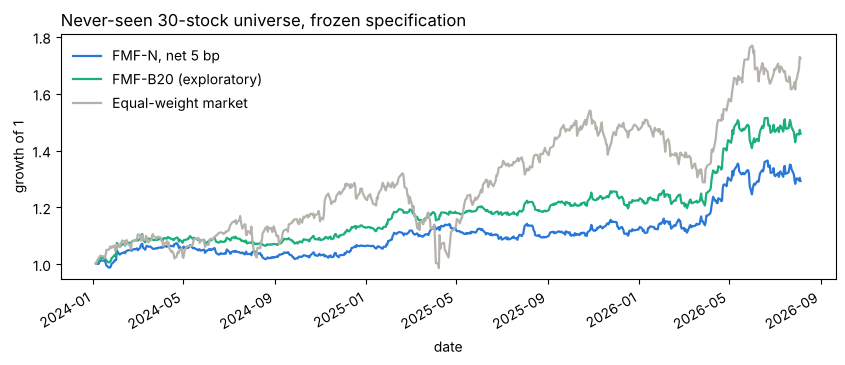

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for name, r, col in (("FMF-N, net 5 bp", oos.net_returns, "#2a78d6"), ("FMF-B20 (exploratory)", b20, "#1baf7a"), ("Equal-weight market", mkt, "#b4b2ab")):
    (1 + r.loc[ev].fillna(0)).cumprod().plot(ax=ax, label=name, color=col, lw=1.6)
ax.set_ylabel("growth of 1"); ax.legend(frameon=False); ax.set_title("Never-seen 30-stock universe, frozen specification", loc="left")
plt.show()

**Against the institutional toolkit.** Every comparable is traded with FMF's exact construction (same legs, allocator, tranches and costs), so only the signal differs.

In [11]:
books = {"FMF-N": oos.net_returns, **comparable_books(oos)}
summary_table(books, {"evaluation": ev}, mkt, reference=oos.net_returns).droplevel(1).sort_values("Sharpe", ascending=False)[["Sharpe", "Calmar", "MaxDD", "beta", "corr ref"]]

,Sharpe,Calmar,MaxDD,beta,corr ref
Time-series momentum 12-1 (CTA-style),1.297,1.623,-0.108,0.427,0.327
Inverse-vol long-only (naive risk parity),1.233,1.011,-0.225,0.880,-0.101
Equal-weight long-only (market),1.142,0.936,-0.253,1.000,-0.092
Target-price momentum (63d),1.136,1.440,-0.075,0.035,0.667
FMF-N,1.046,1.319,-0.080,-0.025,1.000
Revision breadth (classic),0.985,1.160,-0.087,-0.010,0.867
Momentum + revisions blend,0.792,0.885,-0.082,0.076,0.663
12-1 momentum (Jegadeesh-Titman),0.596,0.619,-0.085,0.085,0.608
6-1 momentum,0.563,0.627,-0.072,0.038,0.630
Residual momentum (Blitz et al.),0.561,0.541,-0.079,0.018,0.659


## 3. Your own data

```python
prices  = load_prices("my_prices.csv")                 # date, stock, price
ratings = load_ratings("my_targets.csv", prices)       # date, estimate_value, stock, analyst
out     = run_strategy(prices, ratings, StrategyConfig.fmf_n().with_(k=None, leg_fraction=0.4))
```

From the command line, `fmflow evaluate --prices ... --ratings ... --placebo --loo` runs the full validation battery. `fmflow register` freezes a specification before you look at the results.